# 02 · Exploratory Data Analysis

Goal: understand the cleaned data before modelling — class balance, signer effects, image statistics, how similar the letters look, and what that means for the model.
Input: `data/interim/metadata_clean.csv` (from notebook 01). All figures are saved to `images/`, and each has a short "what it tells us" note below it.

In [1]:
%pip install imagehash opencv-python pillow scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # make `src` importable when running from notebooks/
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, data_utils

sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
config.IMAGES_DIR.mkdir(exist_ok=True); config.INTERIM_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.IMAGES_DIR / name, dpi=150, bbox_inches="tight"); print("saved images/" + name)

from PIL import Image
clean = pd.read_csv(config.INTERIM_DIR / "metadata_clean.csv")
raw_path = config.INTERIM_DIR / "metadata_all_with_flags.csv"
raw = pd.read_csv(raw_path) if raw_path.exists() else None
clean["letter"] = pd.Categorical(clean.letter, categories=config.LETTERS, ordered=True)
print(clean.shape)
display(clean.head(3))

(63291, 29)


,path,rel_path,ext,size_bytes,kind,user,letter,frame,has_depth_pair,readable,...,contrast,sharpness,phash,dup_exact,dup_near,too_small,bad_brightness,blank,sharp_outlier,invalid_label
0,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0002.png,.png,26194,color,A,a,0_0002,True,True,...,58.314086,1927.472168,c0c3e139c370fe39,False,False,False,False,False,False,False
1,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0003.png,.png,27343,color,A,a,0_0003,True,True,...,59.409020,1967.402421,c043e131c370fe7d,False,False,False,False,False,False,False
2,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0005.png,.png,26075,color,A,a,0_0005,True,True,...,59.138359,2019.667226,c0c3e139c170feb9,False,False,False,False,False,False,False


## 1. Dataset overview

In [3]:
print(f"Images: {len(clean):,} | Classes: {clean.letter.nunique()} | Signers: {clean.user.nunique()}")
print("Missing values per column:"); display(clean.isna().sum()[clean.isna().sum() > 0].to_frame("missing") if clean.isna().any().any() else "none")
display(clean[["width", "height", "brightness", "contrast", "sharpness", "size_bytes"]].describe().T.round(2))

Images: 63,291 | Classes: 24 | Signers: 5
Missing values per column:


,missing
error,63291


,count,mean,std,min,25%,50%,75%,max
width,63291.0,102.97,31.77,64.00,78.00,92.00,123.00,249.00
height,63291.0,144.02,23.96,64.00,129.00,145.00,159.00,272.00
brightness,63291.0,98.75,27.51,36.38,78.00,94.63,116.43,200.14
contrast,63291.0,61.42,10.56,26.67,53.20,61.43,69.53,92.42
sharpness,63291.0,1883.05,679.78,146.53,1377.64,1851.15,2311.39,5064.10
size_bytes,63291.0,28984.28,9835.31,7727.00,22109.50,26597.00,33721.00,103875.00


## 2. Class distribution (target variable)

saved images/02_class_distribution.png


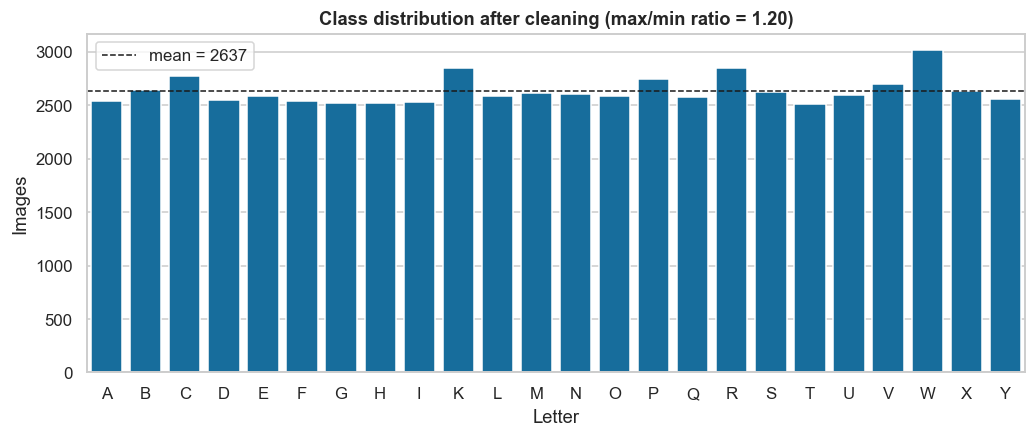

Imbalance ratio (largest/smallest class): 1.20  |  smallest: T (2516)  largest: W (3020)


In [4]:
counts = clean.letter.value_counts().sort_index()
ratio = counts.max() / counts.min()

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=counts.index.str.upper(), y=counts.values, color=sns.color_palette()[0], ax=ax)
ax.axhline(counts.mean(), color="k", ls="--", lw=1, label=f"mean = {counts.mean():.0f}")
ax.set_xlabel("Letter"); ax.set_ylabel("Images"); ax.set_title(f"Class distribution after cleaning (max/min ratio = {ratio:.2f})"); ax.legend()
save(fig, "02_class_distribution.png"); plt.show()
print(f"Imbalance ratio (largest/smallest class): {ratio:.2f}  |  smallest: {counts.idxmin().upper()} ({counts.min()})  largest: {counts.idxmax().upper()} ({counts.max()})")

**What it tells us:** read the imbalance ratio in the title. If it is well above 1, a model trained on this as-is will favour the large classes and plain accuracy will
overstate performance on the small ones. That is why notebook 03 builds a balanced subset (equal images per class) and why we report per-class metrics.

## 3. Signers (users) and class × signer coverage

saved images/02_signer_and_class_by_signer.png


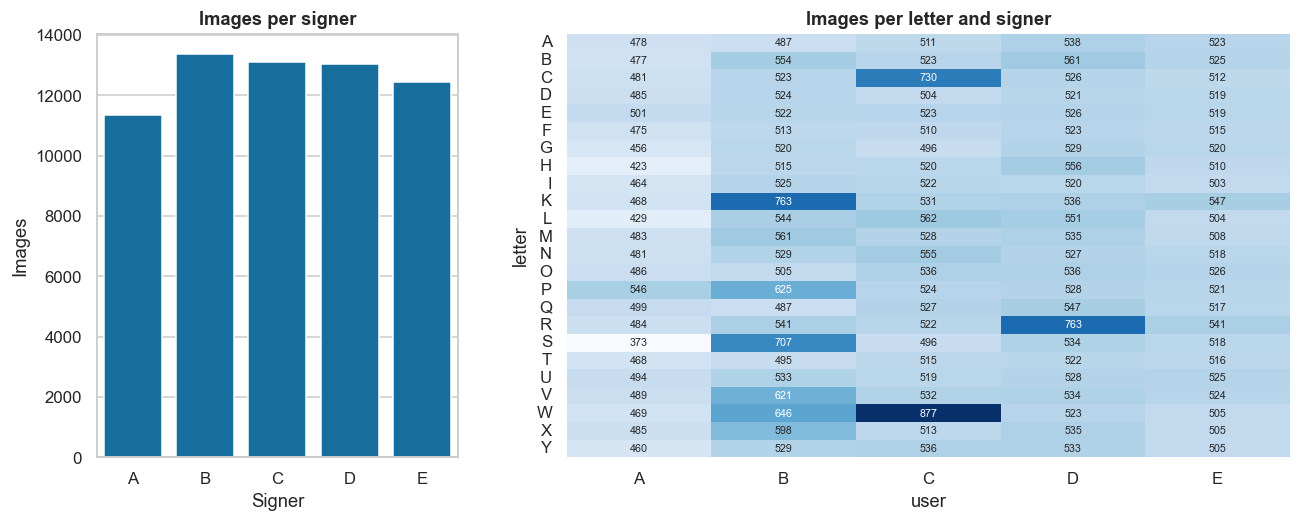

In [5]:
by_user = clean.user.value_counts().sort_index()
pivot = clean.pivot_table(index="letter", columns="user", values="path", aggfunc="count", observed=False).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2]})
sns.barplot(x=by_user.index, y=by_user.values, color=sns.color_palette()[0], ax=axes[0])
axes[0].set_title("Images per signer"); axes[0].set_xlabel("Signer"); axes[0].set_ylabel("Images")
sns.heatmap(pivot, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("Images per letter and signer"); axes[1].set_yticklabels([t.get_text().upper() for t in axes[1].get_yticklabels()], rotation=0)
save(fig, "02_signer_and_class_by_signer.png"); plt.show()

**What it tells us:** each letter is performed by several signers, so signer identity is a *confounder*: frames from one signer look alike (same hand, same background, same lighting).
A random train/test split lets the model see every signer during training, which gives optimistic accuracy; a signer-independent split is the honest test of generalisation (see notebook 03).

## 4. Image formats and sizes (why resizing is needed)

saved images/02_image_size_distribution.png


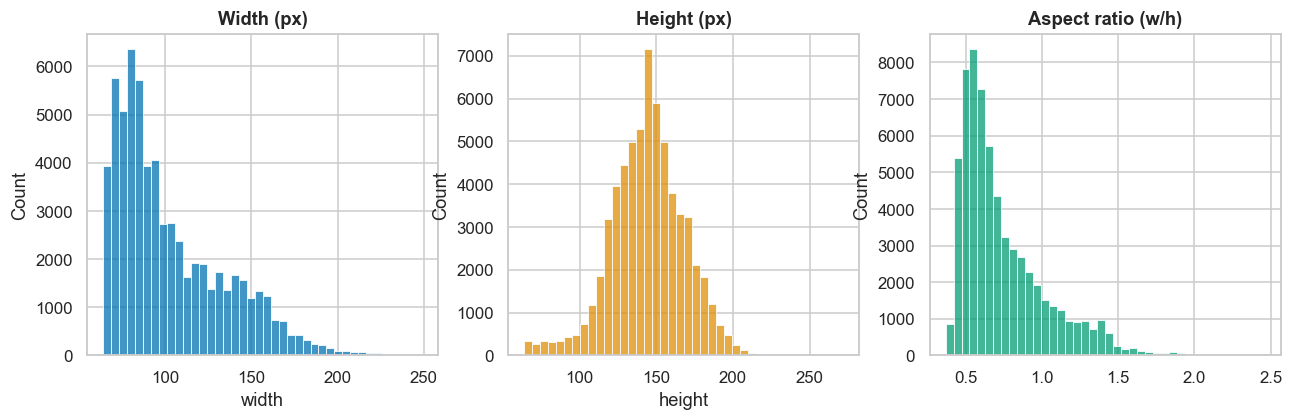

Modes: {'RGB': 63291} | distinct sizes: 12542


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(clean.width, bins=40, ax=axes[0], color=sns.color_palette()[0]); axes[0].set_title("Width (px)")
sns.histplot(clean.height, bins=40, ax=axes[1], color=sns.color_palette()[1]); axes[1].set_title("Height (px)")
sns.histplot(clean.width / clean.height, bins=40, ax=axes[2], color=sns.color_palette()[2]); axes[2].set_title("Aspect ratio (w/h)")
save(fig, "02_image_size_distribution.png"); plt.show()
print("Modes:", clean["mode"].value_counts().to_dict(), "| distinct sizes:", clean.groupby(["width", "height"]).ngroups)

**What it tells us:** the frames are hand crops of varying size and aspect ratio (hand detector output), not a fixed resolution. A CNN needs a fixed input, so every image is resized to
100×100 and converted to RGB in preprocessing; the aspect-ratio spread tells us some distortion is unavoidable with a plain resize.

## 5. Pixel-level statistics: brightness, contrast, sharpness

saved images/02_quality_feature_histograms.png


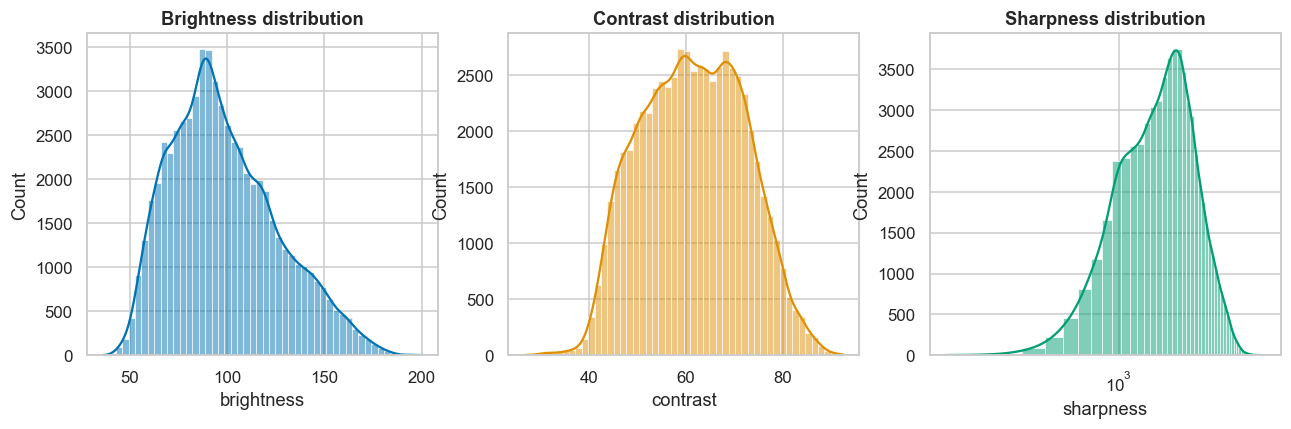

          brightness  contrast  sharpness
skewness        0.55      0.03       0.38


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, c in zip(axes, ["brightness", "contrast", "sharpness"], sns.color_palette()[:3]):
    sns.histplot(clean[col], bins=50, kde=True, ax=ax, color=c); ax.set_title(f"{col.capitalize()} distribution")
    if col == "sharpness": ax.set_xscale("log")
save(fig, "02_quality_feature_histograms.png"); plt.show()
print(clean[["brightness", "contrast", "sharpness"]].skew().round(2).to_frame("skewness").T)

saved images/02_boxplots_by_class.png


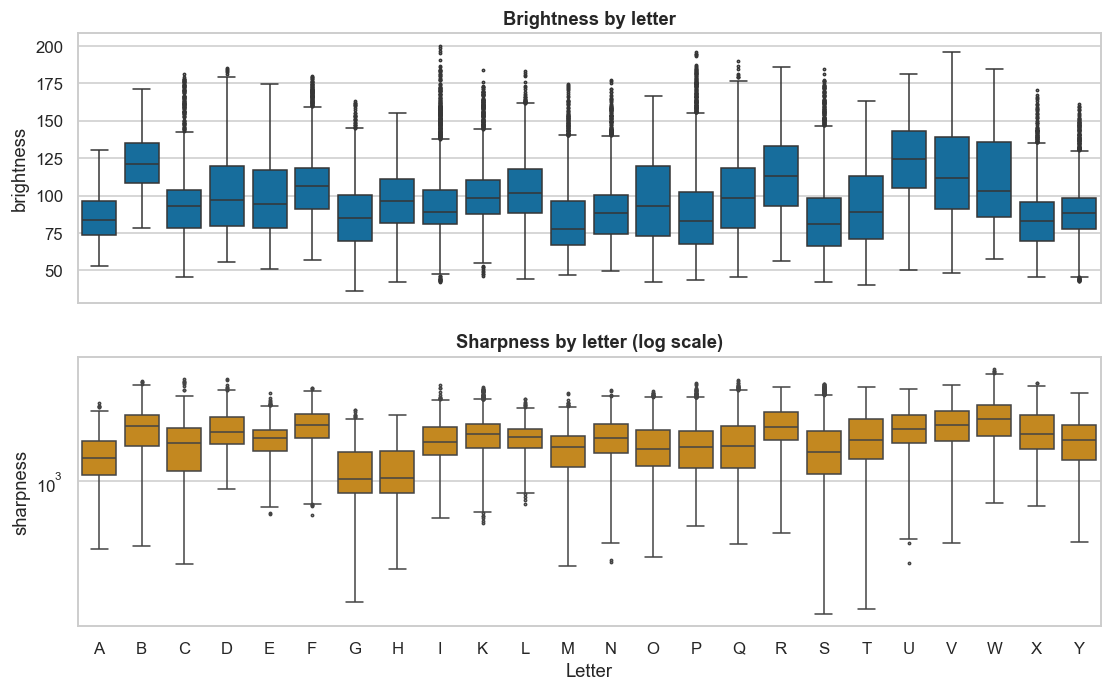

saved images/02_boxplots_by_user.png


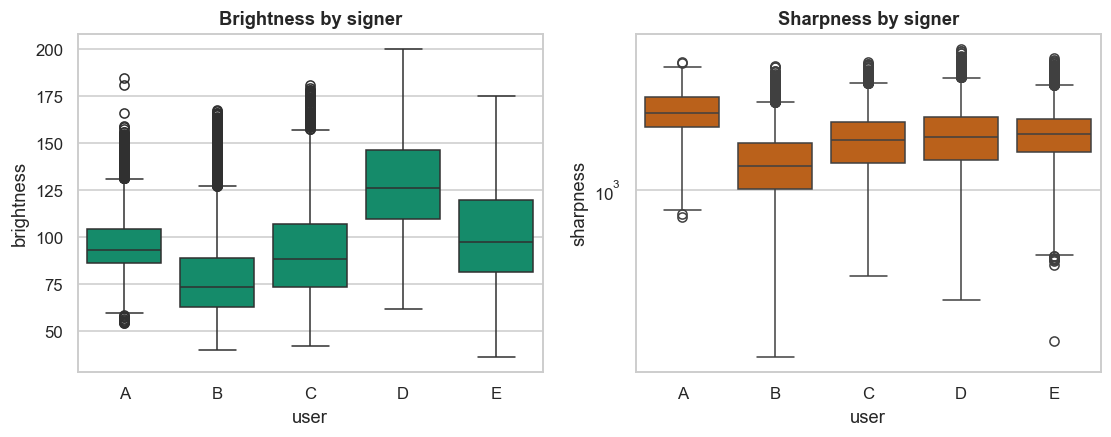

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sns.boxplot(data=clean, x="letter", y="brightness", ax=axes[0], color=sns.color_palette()[0], fliersize=1.5)
axes[0].set_title("Brightness by letter"); axes[0].set_xlabel("")
sns.boxplot(data=clean, x="letter", y="sharpness", ax=axes[1], color=sns.color_palette()[1], fliersize=1.5)
axes[1].set_yscale("log"); axes[1].set_title("Sharpness by letter (log scale)")
axes[1].set_xticklabels([t.get_text().upper() for t in axes[1].get_xticklabels()]); axes[1].set_xlabel("Letter")
save(fig, "02_boxplots_by_class.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=clean, x="user", y="brightness", ax=axes[0], color=sns.color_palette()[2]); axes[0].set_title("Brightness by signer")
sns.boxplot(data=clean, x="user", y="sharpness", ax=axes[1], color=sns.color_palette()[3]); axes[1].set_yscale("log"); axes[1].set_title("Sharpness by signer")
save(fig, "02_boxplots_by_user.png"); plt.show()

**What they tell us:** compare the spread *between signers* with the spread *between letters*. If these features differ by signer but not by letter, the model could
accidentally learn the signer/lighting instead of the hand shape. That is the motivation for scaling inputs (below and in notebook 03) and for evaluating on unseen signers.

## 6. Correlation between numeric features

saved images/02_correlation_heatmap.png


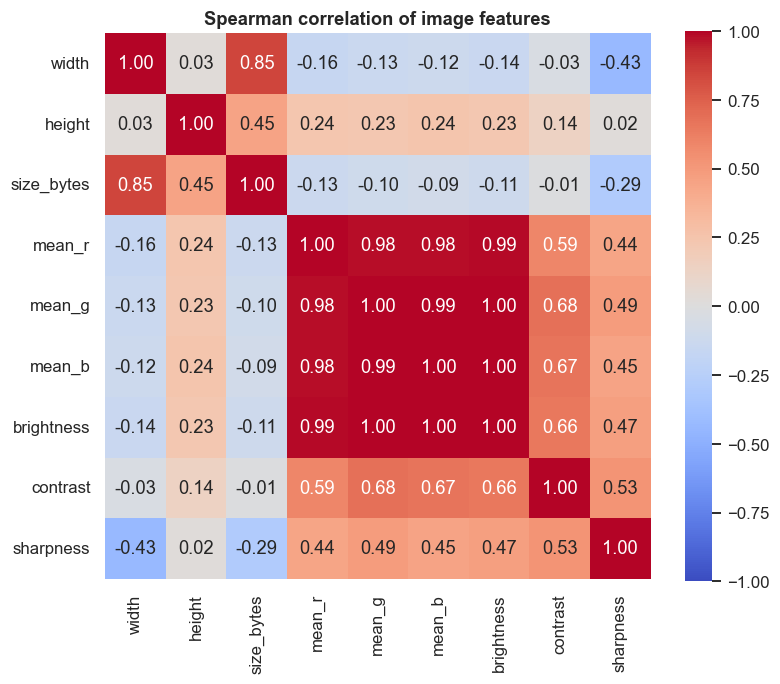

,a,b,rho
42,mean_g,brightness,1.00
51,mean_b,brightness,1.00
41,mean_g,mean_b,0.99
33,mean_r,brightness,0.99
32,mean_r,mean_b,0.98


In [9]:
num = ["width", "height", "size_bytes", "mean_r", "mean_g", "mean_b", "brightness", "contrast", "sharpness"]
corr = clean[num].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation of image features")
save(fig, "02_correlation_heatmap.png"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "a", "level_1": "b"}))
top_corr = pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(5)
display(top_corr.round(2))

**What it tells us:** strongly correlated features are redundant (e.g. width, height and file size grow together; R/G/B means track brightness). Since the model learns from raw pixels
rather than these summary numbers, this mostly confirms that size and brightness are linked, which is another reason to normalise inputs.

## 7. What do the images look like? Samples and per-class mean images

In [11]:
def fix_path(p):
    p = str(p).replace("\\", "/")
    rel = p.split("data/raw/")[-1]          # "dataset5/B/a/color_0_0387.png"
    return str(config.ROOT / "data" / "raw" / rel)

clean["path"] = clean["path"].map(fix_path)

ok = clean["path"].map(lambda p: Path(p).exists())
print(f"Files found: {ok.mean():.1%} ({ok.sum():,} / {len(ok):,})")
print(clean["path"].iloc[0])

Files found: 100.0% (63,291 / 63,291)
C:\Users\HP\Desktop\semester_7\Data Science\project\hand-sign-recognition\data\raw\dataset5\A\a\color_0_0002.png


saved images/02_sample_per_class.png


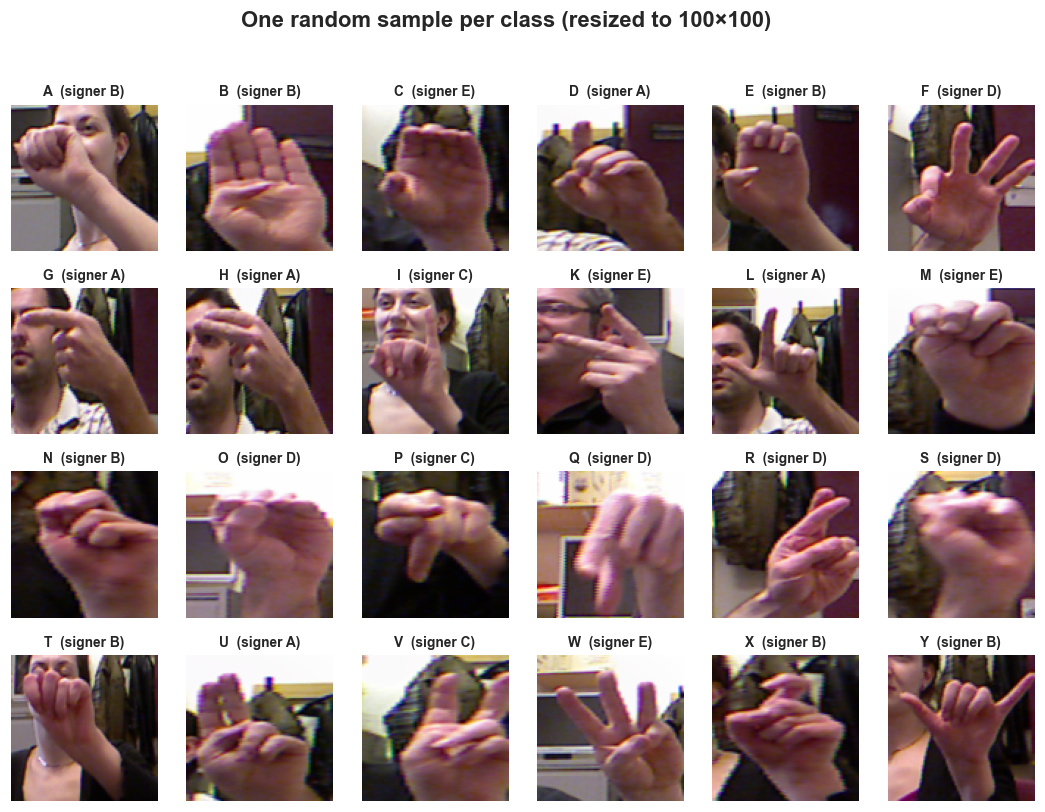

In [12]:
rng = np.random.default_rng(config.SEED)
letters = config.LETTERS
def thumb(p): return np.asarray(data_utils.load_for_model(p, 100))

fig, axes = plt.subplots(4, 6, figsize=(12, 8.3))
for ax, l in zip(axes.ravel(), letters):
    row = clean[clean.letter == l].sample(1, random_state=int(rng.integers(1e6))).iloc[0]
    ax.imshow(thumb(row.path)); ax.set_title(f"{l.upper()}  (signer {row.user})", fontsize=9); ax.axis("off")
fig.suptitle("One random sample per class (resized to 100×100)", fontweight="bold")
save(fig, "02_sample_per_class.png"); plt.show()

saved images/02_mean_image_per_class.png


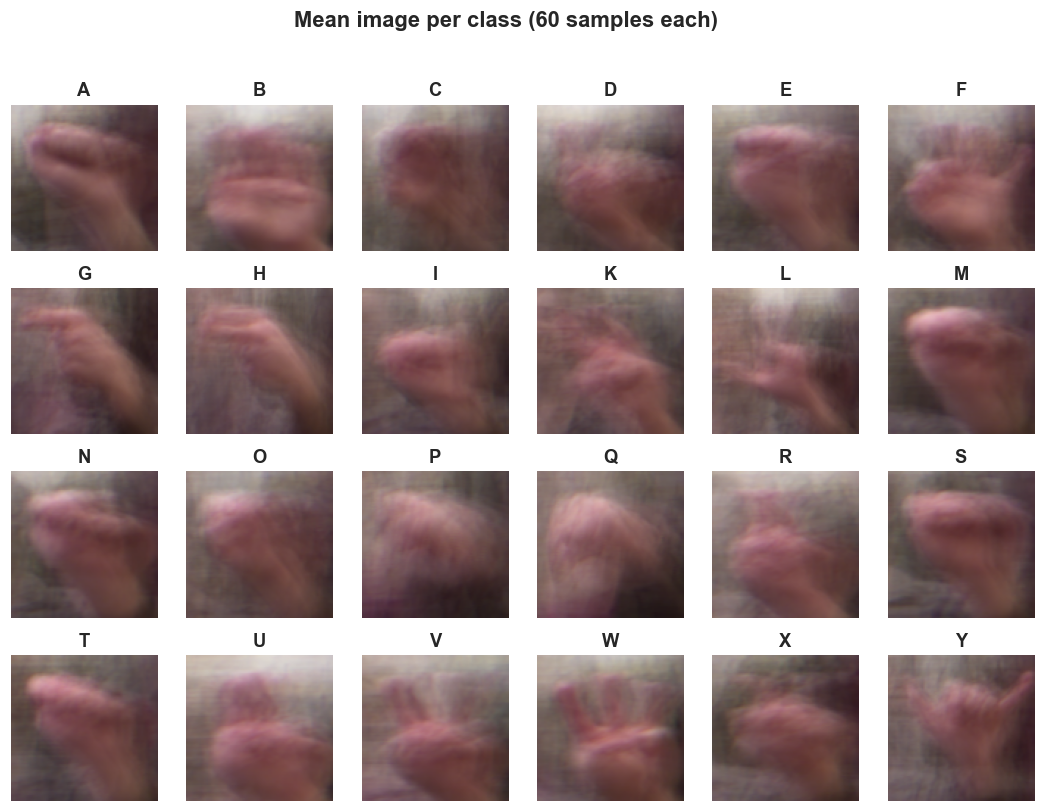

In [13]:
means = {}
for l in letters:
    sub = clean[clean.letter == l].sample(min(60, (clean.letter == l).sum()), random_state=config.SEED)
    means[l] = np.mean([thumb(p) for p in sub.path], axis=0)

fig, axes = plt.subplots(4, 6, figsize=(12, 8.3))
for ax, l in zip(axes.ravel(), letters):
    ax.imshow(means[l].astype("uint8")); ax.set_title(l.upper()); ax.axis("off")
fig.suptitle("Mean image per class (60 samples each)", fontweight="bold")
save(fig, "02_mean_image_per_class.png"); plt.show()

**What it tells us:** the mean images show how consistently each letter is framed. Sharp, hand-shaped means = consistent pose/position; washed-out means = high variation in position, size or background.

## 8. Which letters look alike? (inter-class similarity)

saved images/02_class_similarity_heatmap.png


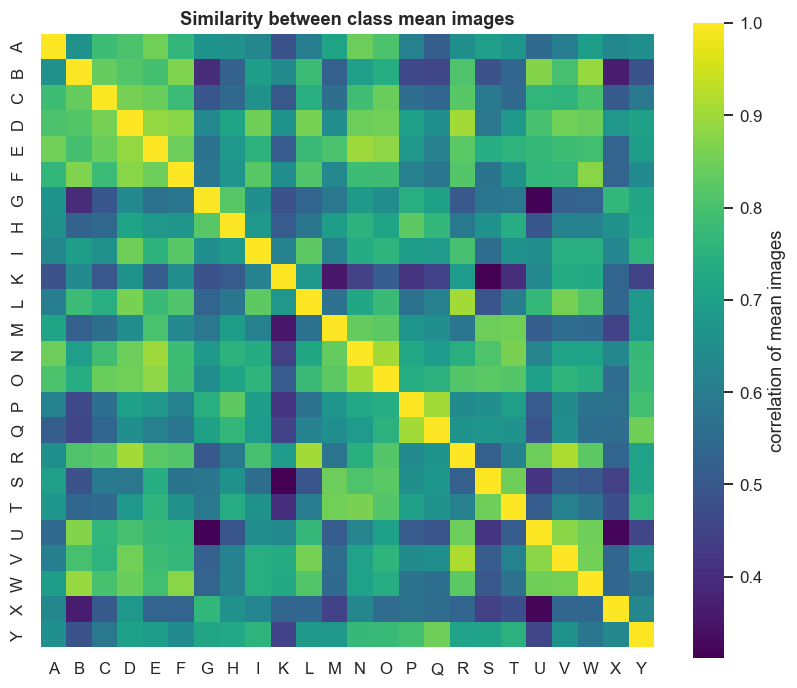

,pair,corr
251,R–V,0.916
210,N–O,0.906
78,D–R,0.905
190,L–R,0.904
231,P–Q,0.903
93,E–N,0.899
42,B–W,0.892
66,D–E,0.889


In [14]:
vecs = np.stack([means[l].mean(axis=2).ravel() for l in letters])   # grey mean image per class
sim = np.corrcoef(vecs)
simdf = pd.DataFrame(sim, index=[l.upper() for l in letters], columns=[l.upper() for l in letters])

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(simdf, cmap="viridis", square=True, ax=ax, cbar_kws={"label": "correlation of mean images"})
ax.set_title("Similarity between class mean images")
save(fig, "02_class_similarity_heatmap.png"); plt.show()

iu = np.triu_indices(len(letters), 1)
sim_pairs = pd.DataFrame({"pair": [f"{letters[i].upper()}–{letters[j].upper()}" for i, j in zip(*iu)], "corr": sim[iu]}).sort_values("corr", ascending=False)
display(sim_pairs.head(8).round(3))

**What it tells us:** the top pairs are the letters most likely to be confused by a classifier. In ASL fingerspelling several letters (for example M/N/S/T or U/V/R) differ only by the position of a thumb or
a finger, so low inter-class variation is expected. After training, check the confusion matrix for exactly these pairs.

## 9. Auto-generated insight summary

In [16]:
user_b = clean.groupby("user").brightness.mean()
user_s = clean.groupby("user").sharpness.median()
kept = len(clean); total = len(raw) if raw is not None else None

lines = [
    "# EDA insights (auto-generated from the data)",
    "",
    f"- **Size:** {kept:,} colour images kept" + (f" out of {total:,} scanned ({kept/total:.1%})" if total else "") + f" after cleaning; {clean.letter.nunique()} classes, {clean.user.nunique()} signers.",
    f"- **Class imbalance:** largest/smallest class ratio = {ratio:.2f}; smallest class {counts.idxmin().upper()} ({counts.min()}), largest {counts.idxmax().upper()} ({counts.max()}).",
    f"- **Formats:** {clean.groupby(['width','height']).ngroups} distinct resolutions, width {clean.width.min()}–{clean.width.max()} px, height {clean.height.min()}–{clean.height.max()} px, modes {clean['mode'].value_counts().to_dict()}; resizing and mode conversion are required.",
    f"- **Signer effect:** mean brightness ranges from {user_b.min():.0f} (signer {user_b.idxmin()}) to {user_b.max():.0f} (signer {user_b.idxmax()}); median sharpness ranges from {user_s.min():.0f} to {user_s.max():.0f}.",
    f"- **Skewness:** sharpness {clean.sharpness.skew():.1f}, brightness {clean.brightness.skew():.1f}, contrast {clean.contrast.skew():.1f} (values above ~1 indicate a strongly right-skewed distribution).",
    f"- **Most correlated features:** " + "; ".join(f"{r.a}/{r.b} ({r.rho:+.2f})" for r in top_corr.head(3).itertuples()) + ".",
    f"- **Most similar letters (mean-image correlation):** " + ", ".join(f"{r.pair} ({r.corr:.2f})" for r in sim_pairs.head(5).itertuples()) + ".",
    "",
    "## Implications for modelling",
    "- Balance the classes (equal images per class) and report per-class precision/recall/F1, not just accuracy.",
    "- Convert every image to RGB and resize to a fixed size; scale pixels to [0, 1] (then standardise with training-set mean/std if the model expects it).",
    "- Split by signer at least once (signer-independent test) in addition to the random split, because frames from one signer are highly correlated.",
    "- Expect confusion between visually similar letters; consider augmentation (small rotations, brightness jitter) to cover lighting differences between signers.",
]
out = config.ROOT / "docs"; out.mkdir(exist_ok=True)
(out / "eda_insights.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines)); print("\nsaved docs/eda_insights.md")

# EDA insights (auto-generated from the data)

- **Size:** 63,291 colour images kept after cleaning; 24 classes, 5 signers.
- **Class imbalance:** largest/smallest class ratio = 1.20; smallest class T (2516), largest W (3020).
- **Formats:** 12542 distinct resolutions, width 64–249 px, height 64–272 px, modes {'RGB': 63291}; resizing and mode conversion are required.
- **Signer effect:** mean brightness ranges from 78 (signer B) to 128 (signer D); median sharpness ranges from 1313 to 2424.
- **Skewness:** sharpness 0.4, brightness 0.5, contrast 0.0 (values above ~1 indicate a strongly right-skewed distribution).
- **Most correlated features:** mean_g/brightness (+1.00); mean_b/brightness (+1.00); mean_g/mean_b (+0.99).
- **Most similar letters (mean-image correlation):** R–V (0.92), N–O (0.91), D–R (0.90), L–R (0.90), P–Q (0.90).

## Implications for modelling
- Balance the classes (equal images per class) and report per-class precision/recall/F1, not just accuracy.
- Convert every ima

## Key findings (read the numbers printed above)
1. **Class imbalance** exists → balance in preprocessing, use per-class metrics.
2. **Signer/lighting variation** is larger than letter-to-letter variation in basic image statistics → normalise, augment, and test on unseen signers.
3. **Inconsistent sizes** → fixed-size RGB tensors are required.
4. **Similar letters** (top pairs in section 8) are the expected error hot-spots.